# LAB 04 — Text Classification trên IMDb
Raw text → representation → classifier → evaluation → error analysis.
Dataset: IMDb 50k reviews (sentiment). Chạy từ trên xuống.

In [1]:
import time, csv, warnings
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from gensim.models import Word2Vec
import preprocessing as pp
warnings.filterwarnings("ignore")
RESULTS = []
def log(exp, cfg, metric, val): RESULTS.append((exp, cfg, metric, val))
def metrics(y, p):
    return dict(accuracy=accuracy_score(y,p), precision=precision_score(y,p), recall=recall_score(y,p), f1=f1_score(y,p))
raw = pp.load_imdb()

## Experiment 1 — Dataset inspection
Không train ngay: kiểm tra số mẫu, số class, phân phối class, độ dài, trùng lặp, thiếu dữ liệu.

n_samples          50000
n_classes          2
class_counts       {'positive': 25000, 'negative': 25000}
class_pct          {'positive': 50.0, 'negative': 50.0}
length_words       {'count': 50000.0, 'mean': 231.2, 'std': 171.3, 'min': 4.0, '25%': 126.0, '50%': 173.0, '75%': 280.0, 'max': 2470.0}
duplicate_reviews  418
missing_text       0
missing_label      0


,Count,Percentage
sentiment,,
positive,25000,50.0
negative,25000,50.0


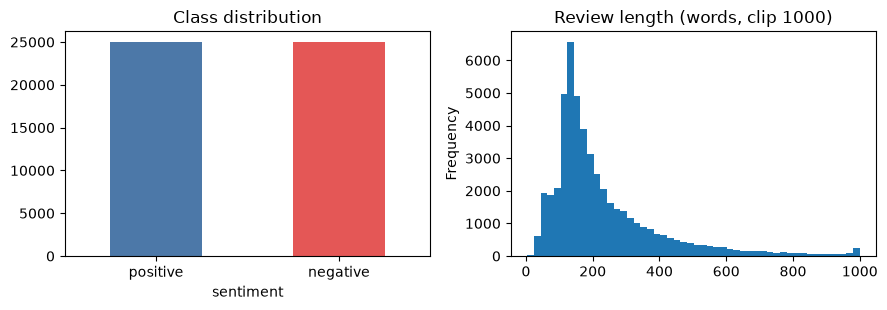

In [2]:
info = pp.inspect(raw)
for k, v in info.items(): print(f"{k:18s}", v)
dist = raw.sentiment.value_counts().rename("Count").to_frame(); dist["Percentage"] = (dist.Count/len(raw)*100).round(2)
display(dist)
fig, ax = plt.subplots(1, 2, figsize=(9,3.2))
dist.Count.plot.bar(ax=ax[0], color=["#4c78a8","#e45756"], rot=0); ax[0].set_title("Class distribution")
raw.review.str.split().str.len().clip(upper=1000).plot.hist(bins=50, ax=ax[1]); ax[1].set_title("Review length (words, clip 1000)")
plt.tight_layout(); plt.savefig("class_distribution.png", dpi=120); plt.show()
log("exp1_inspect", "imdb", "samples", info["n_samples"]); log("exp1_inspect", "imdb", "duplicates", info["duplicate_reviews"])
log("exp1_inspect", "imdb", "median_words", info["length_words"]["50%"])

**Dataset có imbalance không?** Không: 25,000 positive và 25,000 negative (50/50), nên accuracy là metric hợp lý ở đây, nhưng vẫn báo cáo precision/recall/F1. Có 418 review trùng; mình bỏ trùng *trước khi split* để cùng một review không nằm ở cả train lẫn test.

## Chia dữ liệu và Data leakage
Pipeline đúng: **split → fit preprocessing trên TRAIN → transform Val/Test → train**. Chia 60/20/20 stratified, seed 2026.

In [3]:
data = pp.prepare(raw)
train, val, test = pp.split(data)
print(len(data), "sau khi bỏ trùng | train/val/test =", len(train), len(val), len(test))
print("positive rate:", [round(d.label.mean(),3) for d in (train, val, test)])
assert not (set(train.text) & set(test.text))   # không review nào nằm ở 2 tập

49578 sau khi bỏ trùng | train/val/test = 29746 9916 9916
positive rate: [np.float64(0.502), np.float64(0.502), np.float64(0.502)]


### Vì sao fit TF-IDF trên toàn bộ dataset là data leakage?

In [4]:
# Minh họa: fit trên TOÀN BỘ (sai) vs chỉ trên TRAIN (đúng)
tr_only = TfidfVectorizer(min_df=2).fit(train.text)
all_fit = TfidfVectorizer(min_df=2).fit(pd.concat([train.text, val.text, test.text]))
test_vocab = set(TfidfVectorizer(min_df=2).fit(test.text).vocabulary_)
leaked = test_vocab & (set(all_fit.vocabulary_) - set(tr_only.vocabulary_))
print("vocab fit trên train :", len(tr_only.vocabulary_))
print("vocab fit trên tất cả:", len(all_fit.vocabulary_), "(+%d từ chỉ xuất hiện nhờ val/test)" % (len(all_fit.vocabulary_)-len(tr_only.vocabulary_)))
print("từ trong vocab của test mà train không có:", len(leaked), "| ví dụ:", sorted(leaked)[:8])
idf_shift = np.mean([abs(all_fit.idf_[all_fit.vocabulary_[w]] - tr_only.idf_[tr_only.vocabulary_[w]]) for w in list(tr_only.vocabulary_)[:2000]])
print("độ lệch IDF trung bình của 2000 từ: %.4f" % idf_shift)
for name, vec in (("fit trên TRAIN (đúng)", tr_only), ("fit trên TẤT CẢ (leak)", all_fit)):
    m = LogisticRegression(max_iter=1000).fit(vec.transform(train.text), train.label)
    f = f1_score(test.label, m.predict(vec.transform(test.text))); print(f"{name:26s} test F1 = {f:.4f}"); log("leakage", name, "test_f1", round(f,4))

vocab fit trên train : 48587
vocab fit trên tất cả: 59481 (+10894 từ chỉ xuất hiện nhờ val/test)
từ trong vocab của test mà train không có: 1782 | ví dụ: ['1000000', '101st', '122', '1500s', '1596', '15s', '16ème', '1853']
độ lệch IDF trung bình của 2000 từ: 0.0516


fit trên TRAIN (đúng)      test F1 = 0.9034


fit trên TẤT CẢ (leak)     test F1 = 0.9029


**Giải thích:** vocabulary và IDF được tính từ thống kê của *toàn bộ* văn bản. Nếu fit trước khi split thì thông tin của test set (từ nào xuất hiện, từ nào hiếm, document frequency) đã đi vào feature của train, nên model gián tiếp "nhìn thấy" test. Điểm số trở nên lạc quan hơn thực tế (ở đây chênh lệch nhỏ vì IMDb lớn, nhưng với dataset nhỏ hoặc nhiều từ hiếm thì có thể đáng kể). Ngoài ra khi triển khai thật, ta không có sẵn văn bản mới để fit.

## Experiment 2 — Baseline: TF-IDF + Logistic Regression

In [5]:
t0 = time.time()
tfidf = TfidfVectorizer(min_df=2, sublinear_tf=True)
Xtr = tfidf.fit_transform(train.text); Xva = tfidf.transform(val.text); Xte = tfidf.transform(test.text)
# chọn C trên VALIDATION
best = None
for C_ in (0.3, 1, 3, 10):
    m = LogisticRegression(C=C_, max_iter=2000).fit(Xtr, train.label)
    f = f1_score(val.label, m.predict(Xva)); print(f"C={C_:<4} val F1 = {f:.4f}")
    if best is None or f > best[0]: best = (f, C_)
t0 = time.time(); lr = LogisticRegression(C=best[1], max_iter=2000).fit(Xtr, train.label); t_lr = time.time()-t0
p_lr = lr.predict(Xte); res_lr = metrics(test.label, p_lr)
print("C chọn:", best[1], "| vocabulary size:", len(tfidf.vocabulary_), "| training time: %.2fs" % t_lr)
base_tab = pd.DataFrame([{"Model":"TF-IDF + LR", **{k: round(v,4) for k,v in res_lr.items()}}]); display(base_tab)
for k, v in res_lr.items(): log("exp2_baseline", "tfidf+lr", k, round(v,4))
log("exp2_baseline", "tfidf+lr", "vocab_size", len(tfidf.vocabulary_)); log("exp2_baseline", "tfidf+lr", "train_time_s", round(t_lr,2))

C=0.3  val F1 = 0.8840


C=1    val F1 = 0.8938


C=3    val F1 = 0.8987


C=10   val F1 = 0.8962


C chọn: 3 | vocabulary size: 48587 | training time: 0.71s


,Model,accuracy,precision,recall,f1
0,TF-IDF + LR,0.9063,0.9002,0.9148,0.9074


## Experiment 3 — Representation comparison
Word2Vec (skip-gram, dim 100, window 5, min_count 5, epochs 5) được huấn luyện **chỉ trên tập train** (không dùng nhãn), review = trung bình vector các từ.

Word2Vec vocab: 32535 | train time: 48.1s


,Representation,Classifier,accuracy,precision,recall,f1,train_s
0,TF-IDF,Logistic Regression,0.9063,0.9002,0.9148,0.9074,0.7105
1,Avg Word2Vec,Logistic Regression,0.8712,0.8656,0.8800,0.8728,0.3237
2,TF-IDF,Linear SVM,0.9060,0.8996,0.9148,0.9072,0.4140


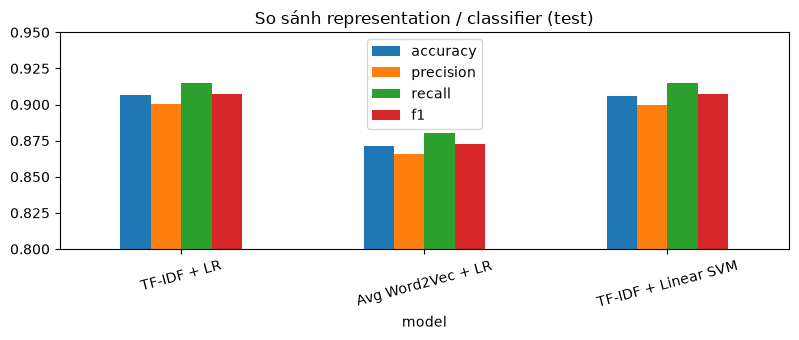

In [6]:
sents = [pp.tokenize(t) for t in train.text]
t0 = time.time(); w2v = Word2Vec(sents, vector_size=100, window=5, min_count=5, epochs=5, sg=1, workers=8, seed=2026); t_w2v = time.time()-t0
print("Word2Vec vocab:", len(w2v.wv), "| train time: %.1fs" % t_w2v)
def avg_vec(text):
    vs = [w2v.wv[w] for w in pp.tokenize(text) if w in w2v.wv]
    return np.mean(vs, axis=0) if vs else np.zeros(100)
Atr = np.array([avg_vec(t) for t in train.text]); Ate = np.array([avg_vec(t) for t in test.text]); Ava = np.array([avg_vec(t) for t in val.text])
t0 = time.time(); lr_w = LogisticRegression(max_iter=2000).fit(Atr, train.label); t_lrw = time.time()-t0
p_w = lr_w.predict(Ate); res_w = metrics(test.label, p_w)
t0 = time.time(); svm = LinearSVC(C=0.5).fit(Xtr, train.label); t_svm = time.time()-t0
p_svm = svm.predict(Xte); res_svm = metrics(test.label, p_svm)
comp = pd.DataFrame([
    {"Representation":"TF-IDF","Classifier":"Logistic Regression", **res_lr, "train_s": t_lr},
    {"Representation":"Avg Word2Vec","Classifier":"Logistic Regression", **res_w, "train_s": t_lrw},
    {"Representation":"TF-IDF","Classifier":"Linear SVM", **res_svm, "train_s": t_svm}]).round(4)
display(comp)
ax = comp.assign(model=comp.Representation + " + " + comp.Classifier.str.replace("Logistic Regression","LR")).set_index("model")[["accuracy","precision","recall","f1"]].plot.bar(figsize=(8,3.5), rot=15, ylim=(0.8,0.95))
ax.set_title("So sánh representation / classifier (test)"); plt.tight_layout(); plt.show()
for _, r in comp.iterrows():
    for k in ("accuracy","precision","recall","f1"): log("exp3_compare", f"{r.Representation}+{r.Classifier}", k, r[k])
log("exp3_compare", "w2v", "w2v_train_time_s", round(t_w2v,1))

### Tại sao hai representation cho kết quả khác nhau?
- **TF-IDF** (sparse, lexical): giữ thông tin từng từ; sentiment trên IMDb phụ thuộc nhiều vào từ đặc trưng (worst, waste, excellent, great) nên Logistic Regression gán trọng số riêng cho từng từ rất hiệu quả.
- **Average Word2Vec** (dense, semantic): mất thứ tự, mỗi từ một vector, trung bình hóa hàng trăm từ vào 100 chiều làm loãng các từ sentiment; ngoài ra Word2Vec học theo context nên `good` và `bad` gần nhau (cos ≈ 0.75) → không tách được cực sentiment.
- Logistic Regression và Linear SVM trên cùng TF-IDF gần như bằng nhau → ở đây **representation ảnh hưởng nhiều hơn classifier**.

### Tại sao hai representation cho kết quả khác nhau?
Xem phần phân tích bên dưới và `reflection.md`: TF-IDF là sparse/lexical, giữ thông tin từng từ (và bigram nếu bật), còn average Word2Vec là dense/semantic nhưng mất thứ tự và trộn tất cả từ vào một vector 100 chiều.

## Experiment 4 — Word order: "good" vs "not good"

In [7]:
S1, S2 = "this movie is good", "this movie is not good"
v1, v2 = avg_vec(S1), avg_vec(S2)
cos = float(v1@v2/np.linalg.norm(v1)/np.linalg.norm(v2))
print("cos(avg(S1), avg(S2)) = %.4f" % cos)
print("w2v neighbors của 'good':", [w for w,_ in w2v.wv.most_similar("good", topn=5)])
print("cos(good, bad) trong w2v = %.3f | cos(good, not) = %.3f" % (w2v.wv.similarity("good","bad"), w2v.wv.similarity("good","not")))
for name, f in (("Avg W2V + LR", lambda s: lr_w.predict_proba([avg_vec(s)])[0,1]), ("TF-IDF unigram + LR", lambda s: lr.predict_proba(tfidf.transform([s]))[0,1])):
    print(f"{name:20s} P(positive): S1 = {f(S1):.3f} | S2 = {f(S2):.3f}")
log("exp4_order", "avg_w2v", "cos_S1_S2", round(cos,4))

cos(avg(S1), avg(S2)) = 0.9765
w2v neighbors của 'good': ['decent', 'great', 'bad', 'nice', 'fine']
cos(good, bad) trong w2v = 0.754 | cos(good, not) = 0.494
Avg W2V + LR         P(positive): S1 = 0.928 | S2 = 0.550
TF-IDF unigram + LR  P(positive): S1 = 0.867 | S2 = 0.395


**Nhận xét:** averaged embedding chỉ *cộng* vector của `not` vào vector chung nên S1 và S2 gần như trùng nhau (cos rất cao) và model gần như cho cùng xác suất. Bag-of-words/TF-IDF unigram cũng thấy `not` và `good` là hai feature riêng, nhưng cộng tuyến tính độc lập nên chỉ bù được một phần; phủ định cần cụm `not good` (bigram) hoặc model có thứ tự.

## Experiment 5 — n-gram features

,Features,Vocabulary,Accuracy,F1,Training time (s)
0,Unigram,48587,0.9063,0.9074,5.2
1,Uni + Bigram,491451,0.9103,0.9115,19.2


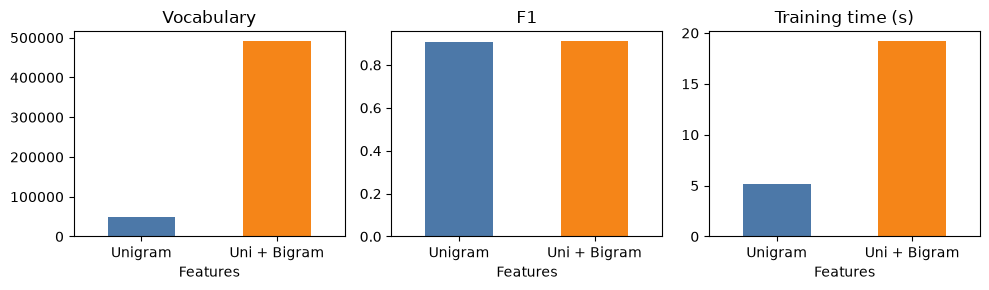

weight 'not good' = -2.946 | 'very good' = 3.093 | 'good' = 2.873


In [8]:
rows = []
for name, ng in (("Unigram",(1,1)), ("Uni + Bigram",(1,2))):
    t0 = time.time(); v = TfidfVectorizer(min_df=2, sublinear_tf=True, ngram_range=ng)
    A = v.fit_transform(train.text); m = LogisticRegression(C=best[1], max_iter=2000).fit(A, train.label); tt = time.time()-t0
    r = metrics(test.label, m.predict(v.transform(test.text)))
    rows.append({"Features":name, "Vocabulary":len(v.vocabulary_), "Accuracy":round(r["accuracy"],4), "F1":round(r["f1"],4), "Training time (s)":round(tt,1)})
    if ng == (1,2): vb, mb = v, m
display(pd.DataFrame(rows))
fig, ax = plt.subplots(1, 3, figsize=(10,3)); d = pd.DataFrame(rows).set_index("Features")
for a, c in zip(ax, ("Vocabulary","F1","Training time (s)")): d[c].plot.bar(ax=a, rot=0, color=["#4c78a8","#f58518"]); a.set_title(c)
plt.tight_layout(); plt.show()
for r in rows:
    for k in ("Vocabulary","F1","Training time (s)"): log("exp5_ngram", r["Features"], k, r[k])
fn = vb.get_feature_names_out(); co = mb.coef_[0]
print("weight 'not good' =", round(co[vb.vocabulary_["not good"]],3), "| 'very good' =", round(co[vb.vocabulary_["very good"]],3), "| 'good' =", round(co[vb.vocabulary_["good"]],3))

**Vì sao bigram giúp nhưng làm feature space lớn hơn?** Bigram như `not good` và `very good` trở thành feature riêng với trọng số riêng nên bắt được phủ định/nhấn mạnh mà unigram bỏ lỡ. Nhưng số cặp từ khác nhau tăng rất nhanh (xem cột Vocabulary), phần lớn xuất hiện hiếm → vector rất thưa, tốn bộ nhớ/thời gian, dễ overfit.

## Evaluation & Confusion matrix
Chọn model tốt nhất theo validation F1 trong 4 cấu hình (tránh chọn theo test).

validation F1: {'TF-IDF + LR': 0.8987, 'Avg W2V + LR': 0.8605, 'TF-IDF + SVM': 0.8979, 'TF-IDF (1-2gram) + LR': 0.9095} → best = TF-IDF (1-2gram) + LR


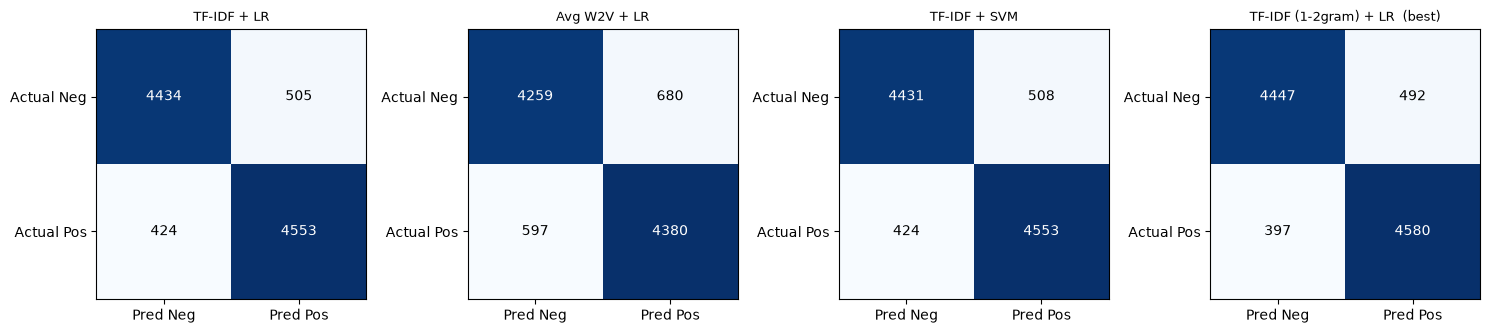

TF-IDF + LR            TN=4434 FP=505 FN=424 TP=4553
Avg W2V + LR           TN=4259 FP=680 FN=597 TP=4380
TF-IDF + SVM           TN=4431 FP=508 FN=424 TP=4553
TF-IDF (1-2gram) + LR  TN=4447 FP=492 FN=397 TP=4580


In [9]:
cands = {"TF-IDF + LR": (p_lr, lr, Xva), "Avg W2V + LR": (p_w, lr_w, Ava), "TF-IDF + SVM": (p_svm, svm, Xva),
         "TF-IDF (1-2gram) + LR": (mb.predict(vb.transform(test.text)), mb, vb.transform(val.text))}
vf1 = {k: f1_score(val.label, c[1].predict(c[2])) for k, c in cands.items()}
bestname = max(vf1, key=vf1.get); print("validation F1:", {k: round(v,4) for k,v in vf1.items()}, "→ best =", bestname)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, (name, c) in zip(axes, cands.items()):
    cm = confusion_matrix(test.label, c[0]); ax.imshow(cm, cmap="Blues")
    ax.set_title(name + ("  (best)" if name == bestname else ""), fontsize=9); ax.set_xticks([0,1]); ax.set_yticks([0,1])
    ax.set_xticklabels(["Pred Neg","Pred Pos"]); ax.set_yticklabels(["Actual Neg","Actual Pos"])
    for i in range(2):
        for j in range(2): ax.text(j, i, cm[i,j], ha="center", va="center", color="white" if cm[i,j] > cm.max()/2 else "black")
plt.tight_layout(); plt.savefig("confusion_matrix.png", dpi=130); plt.show()
for name, c in cands.items():
    tn, fp, fn_, tp = confusion_matrix(test.label, c[0]).ravel(); print(f"{name:22s} TN={tn} FP={fp} FN={fn_} TP={tp}")
    log("confusion", name, "TN_FP_FN_TP", f"{tn},{fp},{fn_},{tp}")

### Phân tích confusion matrix (model tốt nhất)
- Model tốt nhất chọn theo **validation** F1: TF-IDF (1-2 gram) + LR → TN = 4447, FP = 492, FN = 397, TP = 4580 (test).
- Loại lỗi nhiều hơn: **FP (492) > FN (397)** → model hay gọi review *negative* là positive hơn là ngược lại; precision (0.903) thấp hơn recall (0.920).
- Metric phản ánh điều đó: **precision** (bị FP kéo xuống). Accuracy gộp hai loại lỗi nên không thấy sự lệch.
- Avg Word2Vec lỗi nhiều hơn rõ rệt (FP 680, FN 597) so với TF-IDF (FP ~505, FN ~424).

## Error analysis (model tốt nhất)

In [10]:
pbest = cands[bestname][0]; texts = test.text.values; y = test.label.values
rng = np.random.RandomState(2026)
ok = rng.choice(np.where(pbest == y)[0], 3, replace=False)
fp_ = np.where((pbest == 1) & (y == 0))[0]; fn_ = np.where((pbest == 0) & (y == 1))[0]
bad = list(rng.choice(fp_, 2, replace=False)) + list(rng.choice(fn_, 2, replace=False))
lab = {0:"negative", 1:"positive"}
show = lambda i: " ".join(texts[i].split()[:60]) + (" ..." if len(texts[i].split()) > 60 else "")
print("== ĐÚNG =="); [print(f"[{lab[y[i]]} → {lab[pbest[i]]}] ({len(texts[i].split())} từ) {show(i)}\n") for i in ok]
print("== SAI =="); [print(f"[{lab[y[i]]} → {lab[pbest[i]]}] ({len(texts[i].split())} từ) {show(i)}\n") for i in bad]
print("FP =", len(fp_), "| FN =", len(fn_), "| độ dài TB review sai: %.0f vs đúng: %.0f" % (np.mean([len(texts[i].split()) for i in np.where(pbest!=y)[0]]), np.mean([len(texts[i].split()) for i in np.where(pbest==y)[0]])))

== ĐÚNG ==
[negative → negative] (126 từ) It seems that the intention of the film was to show the aggressive (maffia-like) character of Russians, or at least of those Russians able to travel outside their big country; that it is too easy to rob a bank in England; and that British police is so inefficient that it cannot find the person who robbed the bank even when ...

[negative → negative] (484 từ) There are two groups of people...those who love every Fellini movie they see and normal people. While I will admit that I have really enjoyed some of his films, I can also honestly say that I can't stand some of them. My opinion, by the way, is not just some knee-jerk reaction--I have seen most of Fellini's films and have ...

[negative → negative] (319 từ) There's a part of me that would like to give this movie a high rating. Considering that it was made in 1953, this is a very courageous movie about transvestites, tackling the issue fairly seriously and sympathetically (and offering the v

FP = 492 | FN = 397 | độ dài TB review sai: 224 vs đúng: 230


### Phân tích 3 mẫu đúng
| # | True → Pred | Nội dung (rút gọn) | Phân tích |
|---|---|---|---|
| 1 | negative → negative | "...aggressive character of Russians ... British police is so inefficient that it cannot find the person who robbed the bank" | Có từ chê rõ (aggressive, inefficient, cannot); "bank" chỉ là nội dung phim. |
| 2 | negative → negative | "...those who love every Fellini movie ... I can't stand some of them" | Review dài, khen xen kẽ nhưng nhiều cụm chê/phủ định (can't stand) nên tổng điểm vẫn negative. |
| 3 | negative → negative | "There's a part of me that would like to give this movie a high rating ..." | Mở đầu nghe tích cực nhưng phần sau có đủ từ chê; review dài nên bằng chứng tổng hợp đủ. |

### Phân tích 4 mẫu sai (2 FP + 2 FN)
| # | True → Pred | Nội dung (rút gọn) | Category | Phân tích |
|---|---|---|---|---|
| 1 | negative → positive | "My dad is a fan of Columbo and I had always disliked the show ... But my senses were tuned to the series ..." | **mixed sentiment / narrative** | Kể quá trình đổi quan điểm, nhắc nhiều từ tích cực (fan, tuned); bag-of-words không biết đâu là kết luận. Nhãn cũng có thể nhiễu. |
| 2 | negative → positive | "Hollywood Hotel was the last movie musical that Busby Berkeley directed ... biggest popular hits" | **domain-specific / plot summary** | Phần nhìn thấy chỉ mô tả lịch sử phim, gần như không có từ cảm xúc; "biggest, popular, hits" nghe tích cực. |
| 3 | positive → negative | "One Night at McCool's ... starts with an awful amount of promise but ... becomes silly and loses its way" | **data noise + lexical ambiguity** | Nội dung đọc như lời chê nên nhãn positive có vẻ lạ → nhiều khả năng nhiễu nhãn; "awful amount of" dùng *awful* như từ nhấn mạnh. |
| 4 | positive → negative | "it just killed me (and everyone else in the audience)! ... belongs into the all-time-250 ... I'm in no way associated with the creators" | **idiom / lexical ambiguity, negation** | "killed me" là cách nói khen/hài hước nhưng nghe tiêu cực; "no way", "make no mistake" là phủ định dùng để nhấn mạnh. |

*Lưu ý:* nguyên nhân là phán đoán sau khi đọc từng mẫu, chưa kiểm chứng bằng thí nghiệm riêng.

**Nhận xét chung:** lỗi tập trung ở review trộn khen/chê hoặc kể chuyện, mô tả thiếu từ cảm xúc, thành ngữ/từ nhấn mạnh và nhiễu nhãn — những chỗ bag-of-words chỉ cộng trọng số từng từ. Độ dài review sai (224 từ) gần bằng review đúng (230 từ) nên lỗi không do review ngắn.

## Inspect model weights (TF-IDF + Logistic Regression)

,pos_feature,pos_weight,neg_feature,neg_weight
0,excellent,10.59,worst,-13.39
1,great,10.42,waste,-10.24
2,perfect,7.28,awful,-9.87
3,loved,6.95,bad,-9.85
4,amazing,6.73,boring,-8.52
5,best,6.04,terrible,-7.81
6,enjoyed,6.00,poor,-7.68
7,brilliant,5.97,horrible,-7.02
8,wonderful,5.88,poorly,-6.70
9,enjoyable,5.69,disappointment,-6.61


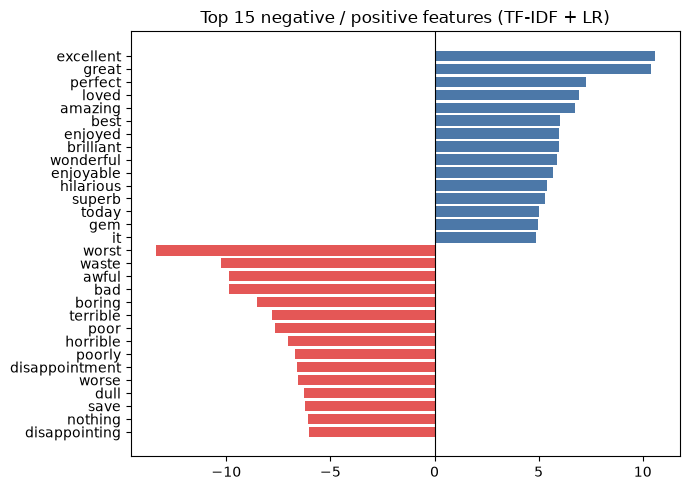

excellent  +10.59
amazing    +6.73
terrible   -7.81
boring     -8.52
not        -4.42
worst      -13.39
great      +10.42
bad        -9.85


In [11]:
names = tfidf.get_feature_names_out(); w = lr.coef_[0]; order = np.argsort(w)
top_pos = pd.DataFrame({"feature": names[order[::-1][:15]], "weight": w[order[::-1][:15]].round(2)})
top_neg = pd.DataFrame({"feature": names[order[:15]], "weight": w[order[:15]].round(2)})
display(pd.concat([top_pos.add_prefix("pos_"), top_neg.add_prefix("neg_")], axis=1))
fig, ax = plt.subplots(figsize=(7,5)); both = pd.concat([top_neg.iloc[::-1], top_pos.iloc[::-1]])
ax.barh(both.feature, both.weight, color=["#e45756"]*15 + ["#4c78a8"]*15); ax.axvline(0, color="k", lw=.8); ax.set_title("Top 15 negative / positive features (TF-IDF + LR)")
plt.tight_layout(); plt.show()
for k in ("excellent","amazing","terrible","boring","not","worst","great","bad"):
    if k in tfidf.vocabulary_: print(f"{k:10s} {w[tfidf.vocabulary_[k]]:+.2f}")
for f_, ww in zip(top_pos.feature, top_pos.weight): log("weights", "top_positive", f_, ww)
for f_, ww in zip(top_neg.feature, top_neg.weight): log("weights", "top_negative", f_, ww)

### Những feature này có ý nghĩa với task không?
- **Có ý nghĩa:** top positive (excellent, great, perfect, loved, amazing) và top negative (worst, waste, awful, bad, boring) đều đúng là từ cảm xúc.
- **Không có ý nghĩa:** `today` (+5.01) và `it` (+4.89) có trọng số dương lớn; nhiều khả năng là tương quan ngẫu nhiên/phong cách viết trong dữ liệu, không phải cảm xúc.
- `not` chỉ −4.42 và unigram không biết `not` đảo nghĩa từ đứng sau → bigram như `not good` mới biểu diễn trực tiếp được phủ định.
- Accuracy cao không đồng nghĩa model dựa vào lý do đúng.

## Application — Sentiment classification
Dự đoán cảm xúc cho review mới bằng model baseline và model bigram (không dữ liệu nào trong này nằm trong tập train/test).

In [12]:
new = ["An absolute masterpiece, the acting was superb and I loved every minute.",
       "Terrible plot and wooden acting. A complete waste of two hours.",
       "I do not like this movie at all.",
       "The film is not bad, actually quite good.",
       "Great visuals but the story was boring and far too long."]
for s in new:
    p1 = lr.predict_proba(tfidf.transform([s]))[0,1]; p2 = mb.predict_proba(vb.transform([s]))[0,1]
    print(f"unigram {p1:.2f} | bigram {p2:.2f} | {s}")

unigram 0.99 | bigram 0.93 | An absolute masterpiece, the acting was superb and I loved every minute.
unigram 0.00 | bigram 0.00 | Terrible plot and wooden acting. A complete waste of two hours.
unigram 0.03 | bigram 0.05 | I do not like this movie at all.
unigram 0.06 | bigram 0.20 | The film is not bad, actually quite good.
unigram 0.31 | bigram 0.15 | Great visuals but the story was boring and far too long.


## Lưu kết quả

In [13]:
with open("results.csv", "w", newline="", encoding="utf8") as f:
    wr = csv.writer(f); wr.writerow(["experiment","config","metric","value"]); wr.writerows(RESULTS)
print(len(RESULTS), "rows → results.csv")

65 rows → results.csv
